# 06 · 阈值与业务评估

使用随机森林预测概率制定优先联系策略。这里的重点不是默认 0.5 阈值，而是营销资源有限时的转化效率与潜在客户覆盖率。

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_score, recall_score
from sklearn.pipeline import Pipeline

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / 'data').exists(): PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
from src.models import build_preprocessor

train = pd.read_csv(PROJECT_ROOT / 'data/processed/train_precall.csv')
test = pd.read_csv(PROJECT_ROOT / 'data/processed/test_precall.csv')
X_train, y_train = train.drop(columns='target_subscription'), train['target_subscription']
X_test, y_test = test.drop(columns='target_subscription'), test['target_subscription']
model = Pipeline([('preprocessor', build_preprocessor(X_train)), ('model', RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced_subsample', n_jobs=-1, random_state=42))])
model.fit(X_train, y_train)
scores = model.predict_proba(X_test)[:, 1]

## 概率阈值策略

In [2]:
rows = []
for threshold in [0.20, 0.30, 0.40, 0.50, 0.60, 0.70]:
    predicted = (scores >= threshold).astype(int)
    contacted = predicted.sum()
    rows.append({
        'threshold': threshold, 'customers_to_contact': contacted,
        'contact_rate': contacted / len(y_test),
        'precision': precision_score(y_test, predicted, zero_division=0),
        'recall': recall_score(y_test, predicted, zero_division=0),
        'expected_conversions': int(((predicted == 1) & (y_test.to_numpy() == 1)).sum()),
    })
threshold_results = pd.DataFrame(rows)
display(threshold_results.style.format({'threshold':'{:.2f}','contact_rate':'{:.1%}','precision':'{:.1%}','recall':'{:.1%}'}))

,threshold,customers_to_contact,contact_rate,precision,recall,expected_conversions
0,0.20,4036,49.0%,18.9%,82.0%,761
1,0.30,2262,27.5%,29.3%,71.4%,663
2,0.40,1539,18.7%,39.2%,65.1%,604
3,0.50,1251,15.2%,45.2%,61.0%,566
4,0.60,1022,12.4%,49.0%,54.0%,501
5,0.70,730,8.9%,56.2%,44.2%,410


## 容量受限策略：优先联系评分最高的客户

In [3]:
ranking = pd.DataFrame({'score': scores, 'actual': y_test.to_numpy()}).sort_values('score', ascending=False).reset_index(drop=True)
capacity_rows = []
for share in [0.05, 0.10, 0.20, 0.30]:
    count = round(len(ranking) * share)
    selected = ranking.head(count)
    conversions = int(selected['actual'].sum())
    capacity_rows.append({'contact_top_share': share, 'customers_to_contact': count, 'actual_conversions': conversions, 'conversion_rate': conversions / count, 'positive_customer_coverage': conversions / y_test.sum()})
capacity_results = pd.DataFrame(capacity_rows)
capacity_results.to_csv(PROJECT_ROOT / 'reports/campaign_capacity_evaluation.csv', index=False)
display(capacity_results.style.format({'contact_top_share':'{:.0%}','conversion_rate':'{:.1%}','positive_customer_coverage':'{:.1%}'}))

,contact_top_share,customers_to_contact,actual_conversions,conversion_rate,positive_customer_coverage
0,5%,412,260,63.1%,28.0%
1,10%,824,436,52.9%,47.0%
2,20%,1647,614,37.3%,66.2%
3,30%,2471,674,27.3%,72.6%


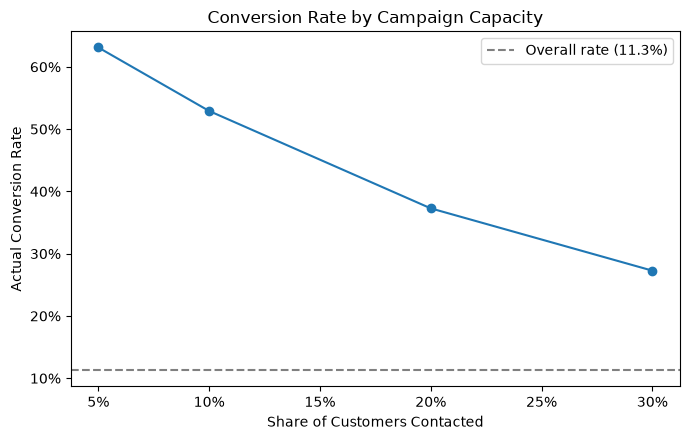

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(capacity_results['contact_top_share'], capacity_results['conversion_rate'], marker='o')
ax.axhline(y=y_test.mean(), color='gray', linestyle='--', label=f'Overall rate ({y_test.mean():.1%})')
ax.set(title='Conversion Rate by Campaign Capacity', xlabel='Share of Customers Contacted', ylabel='Actual Conversion Rate')
ax.xaxis.set_major_formatter(lambda x, _: f'{x:.0%}')
ax.yaxis.set_major_formatter(lambda y, _: f'{y:.0%}')
ax.legend()
fig.tight_layout()
fig.savefig(PROJECT_ROOT / 'figures/modeling/capacity_strategy.png', dpi=160, bbox_inches='tight')
plt.show()

## 建议

将有限资源优先分配给评分最高的一批客户；具体比例应结合单次电话成本、单笔定期存款收益和团队容量确定。